# Known-input amplification of a thermal preparation

The source circuit prepares a Bell purification from all-zero wires and applies an explicit Pauli LCU approximation to an imaginary-time filter. This notebook amplifies the **known prepared input** by reflecting about all input wires. It keeps the accepted purification's direction, including a possible global sign, while the thermal-polynomial bias remains unchanged.

The fixed model is $H/E_0=0.6Z+0.4X$, $E_0=k_B=1$, Taylor degree 6 and default $\beta=1.25/E_0$. One system, one reference and two label qubits give four wires. The primary amplitude-amplification identity is due to Brassard et al. (2000 preprint, published 2002); this implementation and its circuit figures are original.


In [1]:
import os
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from qiskit import QuantumCircuit
from qiskit.quantum_info import Operator

root = Path.cwd()
if not (root / "src/openquantum/simulation/preparation_amplification.py").exists() and (root.parent / "src/openquantum/simulation/preparation_amplification.py").exists():
    root = root.parent
if (root / "src/openquantum/simulation/preparation_amplification.py").exists():
    sys.path.insert(0, str(root / "src"))
    from openquantum.simulation import preparation_amplification as pa, thermal_filter as tf
else:
    sys.path.insert(0, str(root))
    import preparation_amplification as pa
    import thermal_filter as tf

terms = ((.6,"Z"),(.4,"X"))
beta, degree, default_round = 1.25, 6, 1
source = tf.build_thermal_filter(terms, beta, degree)
labels = list(range(source.metadata["n_system"] + source.metadata["n_reference"], source.num_qubits))


## Reflections and the actual access

The success reflection $S_f=I-2\Pi_{\mathrm{labels}=0}$ acts as identity on system and reference. The initial reflection $S_0=I-2|0_{\mathrm{all}}\rangle\langle0_{\mathrm{all}}|$ acts on the **whole input**. Both are X–MCZ–X circuits. Starting with $A$, each chronological round is $S_f,A^\dagger,S_0,A$, with the required global $\pi$ phase, so $Q=-AS_0A^\dagger S_f$.

The boxes below have actual circuit definitions: $A$ contains Bell preparation and PREPARE/SELECT/unprepare. Resource counting uses the fully expanded circuits, and all reference wires stay coherent until amplification finishes.


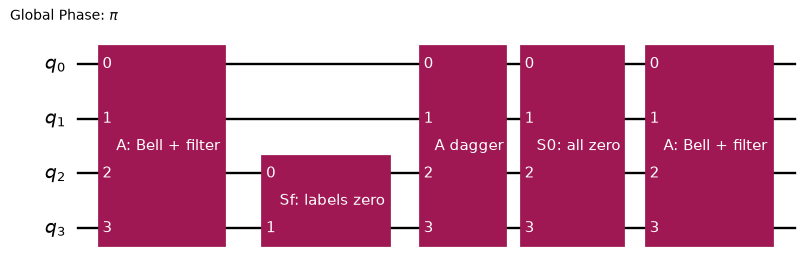

In [2]:
diagram = QuantumCircuit(source.num_qubits)
diagram.append(source.to_gate(label="A: Bell + filter"), range(source.num_qubits))
diagram.append(pa.zero_subregister_reflection(len(labels), range(len(labels))).to_gate(label="Sf: labels zero"), labels)
diagram.append(source.inverse().to_gate(label="A dagger"), range(source.num_qubits))
diagram.append(pa.zero_subregister_reflection(source.num_qubits, range(source.num_qubits)).to_gate(label="S0: all zero"), range(source.num_qubits))
diagram.append(source.to_gate(label="A: Bell + filter"), range(source.num_qubits))
diagram.global_phase += np.pi
fig = diagram.draw(output="mpl", fold=28, scale=.85)
display(fig)
plt.close(fig)


## Signed direction and the reduced thermal state

For $p=\|\Pi_f A|0\rangle\|^2$ and $\theta=\arcsin\sqrt p$, the accepted branch is multiplied by $\sin[(2r+1)\theta]/\sqrt p$. A negative factor changes only its global sign. We check the raw signed branch first, then phase-invariant purification error and the reduced density matrix. The Gibbs trace-distance bias comes from the source polynomial and cannot be removed by this amplification.


In [3]:
checks = [pa.preparation_amplification_check(terms, b, degree, r) for b in (1.25,2.0) for r in range(5)]
columns = ["beta", "rounds", "actual_acceptance_probability", "expected_global_sign",
           "raw_signed_accepted_vector_error", "phase_invariant_purification_error",
           "reduced_state_trace_distance_from_baseline", "gibbs_trace_distance", "energy_error"]
display(pd.DataFrame(checks)[columns])
assert max(c["raw_signed_accepted_vector_error"] for c in checks) < 1e-10
assert max(c["reduced_state_trace_distance_from_baseline"] for c in checks) < 1e-10
core = pa.build_preparation_amplification(terms, beta, degree, default_round)
compiled = pa.decompose_preparation_amplification(core)
assert core.num_qubits <= pa.MAX_OPERATOR_QUBITS
whole_unitary_error = float(np.max(np.abs(Operator(core).data - Operator(compiled).data)))
print(f"Full four-wire source/primitive unitary max-entry error: {whole_unitary_error:.3g}")
print("Lowering uses qubits_initially_zero=False; these in-memory phase checks retain the overall phase.")
contrast = pa.ancilla_only_distortion_check(terms, beta, degree, default_round)
print(f"Ancilla-only contrast changes the original thermal-polynomial state by trace distance {contrast['trace_distance_from_original_thermal_polynomial_state']:.6f}.")


,beta,rounds,actual_acceptance_probability,expected_global_sign,raw_signed_accepted_vector_error,phase_invariant_purification_error,reduced_state_trace_distance_from_baseline,gibbs_trace_distance,energy_error
0,1.25,0,0.468590,1,0.000000e+00,0.000000e+00,0.000000e+00,3.933638e-07,5.673173e-07
1,1.25,1,0.593733,1,1.280314e-15,4.488303e-17,2.801422e-17,3.933638e-07,5.673173e-07
2,1.25,2,0.345422,-1,4.655987e-16,4.656793e-16,3.775360e-16,3.933638e-07,5.673173e-07
3,1.25,3,0.712982,-1,3.778344e-15,3.882844e-16,2.516576e-16,3.933638e-07,5.673173e-07
4,1.25,4,0.231976,1,4.525810e-16,7.662758e-16,5.460727e-16,3.933638e-07,5.673173e-07
5,2.00,0,0.400833,1,0.000000e+00,0.000000e+00,0.000000e+00,4.878973e-06,7.036554e-06
6,2.00,1,0.781897,1,2.122979e-15,2.575987e-16,2.566311e-16,4.878973e-06,7.036554e-06
7,2.00,2,0.079728,-1,6.805423e-16,6.709297e-16,5.826669e-16,4.878973e-06,7.036554e-06
8,2.00,3,0.992520,-1,4.767495e-15,2.254491e-16,1.284267e-16,4.878973e-06,7.036554e-06
9,2.00,4,0.012728,-1,3.798642e-15,2.681860e-15,1.096542e-15,4.878973e-06,7.036554e-06


Full four-wire source/primitive unitary max-entry error: 1.31e-15
Lowering uses qubits_initially_zero=False; these in-memory phase checks retain the overall phase.
Ancilla-only contrast changes the original thermal-polynomial state by trace distance 0.813256.


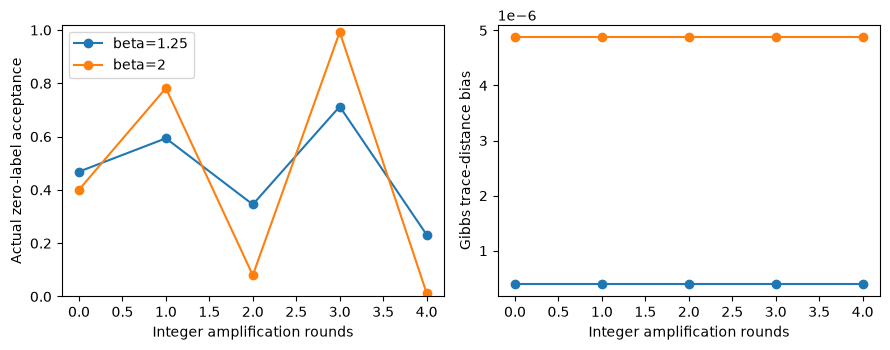

In [4]:
fig, axes = plt.subplots(1,2,figsize=(9,3.6))
for b in (1.25,2.0):
    selected = [c for c in checks if c["beta"] == b]
    axes[0].plot([c["rounds"] for c in selected], [c["actual_acceptance_probability"] for c in selected], "o-", label=f"beta={b:g}")
    axes[1].plot([c["rounds"] for c in selected], [c["gibbs_trace_distance"] for c in selected], "o-")
axes[0].set(xlabel="Integer amplification rounds", ylabel="Actual zero-label acceptance", ylim=(0,1.02))
axes[1].set(xlabel="Integer amplification rounds", ylabel="Gibbs trace-distance bias")
axes[1].ticklabel_format(axis="y",style="sci",scilimits=(0,0))
axes[0].legend()
fig.tight_layout()
display(fig)
plt.close(fig)


## Complete attempts and separate energy groups

Every complete attempt resets all wires, runs the whole amplified unitary, measures the labels, resets the reference **without conditioning**, changes the system basis and reads the system. Failed attempts run this same schedule and are charged in full. The noncommuting energy mean is $0.6\langle Z\rangle+0.4\langle X\rangle$, so X and Z need separate accepted samples.

The tables are logical counts and **unexecuted workload proposals**. Coherent rotation synthesis, physical gate/reset/readout errors, scheduling and error correction remain unavailable. Hypothetical synthesis allowances cover every $A$, inverse and reflection call; irreversible reset/readout faults are separate.


In [5]:
count_rows, workload_rows = [], []
for r in range(5):
    check = next(c for c in checks if c["beta"] == beta and c["rounds"] == r)
    workload = tf.thermal_energy_workload(check["actual_acceptance_probability"], terms=terms)
    proposal = pa.synthesis_conditioning_proposal(check["actual_acceptance_probability"], r)
    workload_rows.append({"rounds":r,"acceptance":check["actual_acceptance_probability"],
                          "source_calls_per_attempt":2*r+1,"accepted_shots_total":workload["total_accepted_shots"],
                          "capped_complete_attempts":workload["worst_case_complete_trials"],
                          "uncapped_expected_complete_attempts":workload["expected_complete_trials"],
                          "hypothetical_coherent_error_allowance":proposal["amplified_coherent_operator_error_allowance"]})
    for axis in ("X","Z"):
        trial = pa.decompose_preparation_amplification(pa.build_preparation_trial(terms,beta,degree,r,axis))
        counts = dict(trial.count_ops())
        count_rows.append({"rounds":r,"basis":axis,"wires":trial.num_qubits,"total_instructions":sum(counts.values()),
                           "dependency_depth":trial.depth(),"CX":counts.get("cx",0),
                           "continuous_rotations":sum(counts.get(g,0) for g in ("rx","ry","rz")),
                           "resets":counts.get("reset",0),"measurements":counts.get("measure",0)})
display(pd.DataFrame(count_rows))
display(pd.DataFrame(workload_rows))
print("No accepted-shot experiment, synthesis certificate or physical estimate is reported.")
print("OpenQASM measured trials omit an overall compiled phase; probabilities remain valid, but coherent controlled reuse requires phase restoration/source modules.")


,rounds,basis,wires,total_instructions,dependency_depth,CX,continuous_rotations,resets,measurements
0,0,X,4,65,45,21,14,5,3
1,0,Z,4,64,45,21,15,5,3
2,1,X,4,211,152,78,62,5,3
3,1,Z,4,210,152,78,63,5,3
4,2,X,4,357,259,135,110,5,3
5,2,Z,4,356,259,135,111,5,3
6,3,X,4,503,366,192,158,5,3
7,3,Z,4,502,366,192,159,5,3
8,4,X,4,649,473,249,206,5,3
9,4,Z,4,648,473,249,207,5,3


,rounds,acceptance,source_calls_per_attempt,accepted_shots_total,capped_complete_attempts,uncapped_expected_complete_attempts,hypothetical_coherent_error_allowance
0,0,0.468590,1,29710,742750,63402.942580,0.00001
1,1,0.593733,3,29710,534780,50039.287377,0.00005
2,2,0.345422,5,29710,1099270,86010.632775,0.00009
3,3,0.712982,7,29710,386230,41670.075327,0.00013
4,4,0.231976,9,29710,1782600,128073.484771,0.00017


No accepted-shot experiment, synthesis certificate or physical estimate is reported.
OpenQASM measured trials omit an overall compiled phase; probabilities remain valid, but coherent controlled reuse requires phase restoration/source modules.


## Size-dependent reflection cost

The structured generation family is $H_n=\sum_i(0.6Z_i+0.4X_i)$. It has an available factorized classical Gibbs answer. The following rows construct the actual Pauli access and reflections for $n=1,2,3$; they do not report state-validation or equal-accuracy Gibbs workloads at those larger sizes. Full-input reflection width is $2n+m$, while the success reflection uses only $m$ label wires.


In [6]:
scaling = pd.DataFrame([pa.reflection_scaling_row(n,beta,degree) for n in (1,2,3)])
columns = ["n_system","n_reference","label_qubits","total_qubits","aggregated_pauli_terms",
           "source_top_level_instructions","full_initial_reflection_primitive_gates",
           "good_label_reflection_primitive_gates","full_initial_reflection_depth","good_label_reflection_depth"]
display(scaling[columns])
source_trial_columns=["n_system","source_coherent_primitive_gates","unamplified_full_X_trial_primitive_operations",
                      "unamplified_full_Z_trial_primitive_operations","unamplified_full_trial_initial_resets",
                      "unamplified_full_trial_reference_resets","unamplified_full_trial_label_measurements",
                      "unamplified_full_trial_system_measurements"]
display(scaling[source_trial_columns])
print("Explicit reset allows specialization in a measured trial; reusable coherent-source counts have a separate full-unitary contract.")
print("Family rows are access/reflection generation counts; finite-K and shot costs do not establish an equal-error size comparison.")


,n_system,n_reference,label_qubits,total_qubits,aggregated_pauli_terms,source_top_level_instructions,full_initial_reflection_primitive_gates,good_label_reflection_primitive_gates,full_initial_reflection_depth,good_label_reflection_depth
0,1,1,2,4,3,24,37,5,28,3
1,2,2,4,8,9,142,391,37,162,28
2,3,3,5,11,27,518,799,62,246,53


,n_system,source_coherent_primitive_gates,unamplified_full_X_trial_primitive_operations,unamplified_full_Z_trial_primitive_operations,unamplified_full_trial_initial_resets,unamplified_full_trial_reference_resets,unamplified_full_trial_label_measurements,unamplified_full_trial_system_measurements
0,1,56,65,64,4,1,2,1
1,2,1200,1010,1008,8,2,4,2
2,3,7608,5710,5707,11,3,5,3


Explicit reset allows specialization in a measured trial; reusable coherent-source counts have a separate full-unitary contract.
Family rows are access/reflection generation counts; finite-K and shot costs do not establish an equal-error size comparison.


## Optional local exploration and scope

Integer rounds are not monotonic. At $\beta=2$, three rounds bring success near 0.9925 and a fourth reduces it near 0.0127. Higher one-attempt success can still require more source/inverse calls per accepted output. No general probability-learning, adaptive or fixed-point method is implemented.

The thermal source limits system width to four, input terms to 32, aggregate terms to 256, degree to 12 and $\beta\sum|c_j|/2$ to 10. The amplification wrapper limits rounds to four and total wires to 24. Its 50,000 source-instruction cap is top-level; nested lowering can cost more before the 250,000-operation export cap is checked. Statevector checks stop at 12 wires and full-operator checks at six. No Lean theorem is claimed.

For standalone Python execution, save `preparation_amplification.py`, `thermal_filter.py` and `lcu.py` beside this notebook and use the project’s pinned Python 3.12 environment. The static site uses the saved labeled outputs without widget objects or a public kernel.


In [7]:
if os.environ.get("OPENQUANTUM_STATIC_BUILD") != "1":
    import ipywidgets as widgets
    def explore(beta=1.25, rounds=1):
        check = pa.preparation_amplification_check(terms,beta,degree,rounds)
        display(pd.DataFrame([{ "beta":beta,"rounds":rounds,"acceptance":check["actual_acceptance_probability"],
                              "global_sign":check["expected_global_sign"],"Gibbs_bias":check["gibbs_trace_distance"]}]))
    display(widgets.interactive(explore,beta=widgets.FloatSlider(min=.5,max=2,step=.25,value=1.25),
                               rounds=widgets.IntSlider(min=0,max=4,value=1)))
